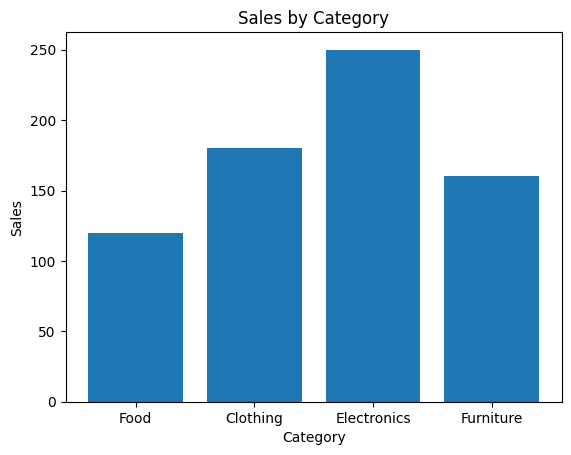

In [5]:

import matplotlib.pyplot as plt

categories = ["Food", "Clothing", "Electronics", "Furniture"]
sales = [120, 180, 250, 160]

plt.bar(categories, sales)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.show()

#Bar Color and Value Label

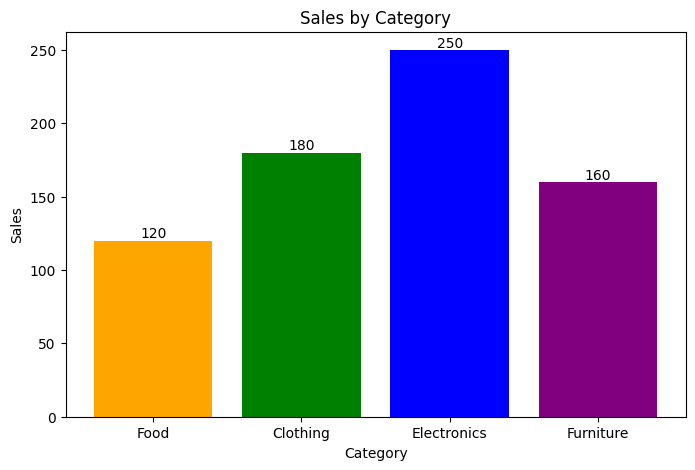

In [6]:

import matplotlib.pyplot as plt

categories = ["Food", "Clothing", "Electronics", "Furniture"]
sales = [120, 180, 250, 160]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    categories,
    sales,
    color=["orange", "green", "blue", "purple"]
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.bar_label(bars)

plt.show()

#Horizontal Bar Chart

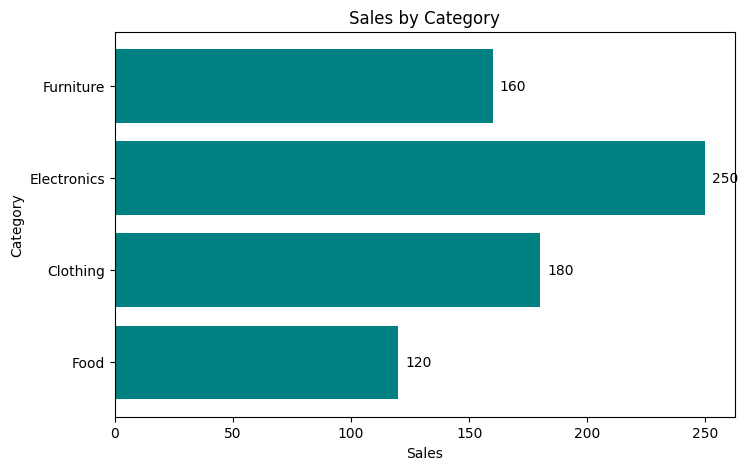

In [7]:

import matplotlib.pyplot as plt

categories = ["Food", "Clothing", "Electronics", "Furniture"]
sales = [120, 180, 250, 160]

plt.figure(figsize=(8, 5))

bars = plt.barh(
    categories,
    sales,
    color="teal"
)

plt.title("Sales by Category")
plt.xlabel("Sales")
plt.ylabel("Category")

plt.bar_label(bars, padding=5)

plt.show()

#Sorting Bars by Sales

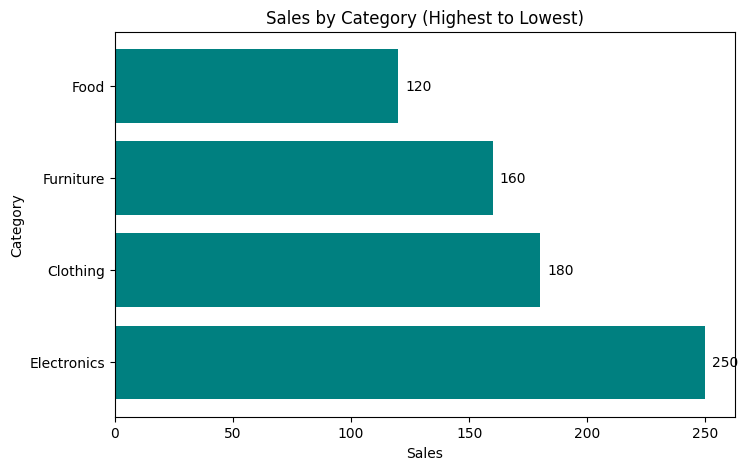

In [8]:

import matplotlib.pyplot as plt

categories = ["Food", "Clothing", "Electronics", "Furniture"]
sales = [120, 180, 250, 160]

# Sort sales in descending order
sorted_data = sorted(
    zip(categories, sales),
    key=lambda item: item[1],
    reverse=True
)

sorted_categories = [item[0] for item in sorted_data]
sorted_sales = [item[1] for item in sorted_data]

plt.figure(figsize=(8, 5))

bars = plt.barh(
    sorted_categories,
    sorted_sales,
    color="teal"
)

plt.title("Sales by Category (Highest to Lowest)")
plt.xlabel("Sales")
plt.ylabel("Category")
plt.bar_label(bars, padding=5)

plt.show()

In [9]:
import pandas as pd

df_clean = pd.read_csv("retail_store_sales_cleaned.csv")

print(df_clean.shape)
df_clean.head()

(10531, 11)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [10]:

print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nColumns:")
print(df_clean.columns.tolist())

print("\nFirst 5 rows:")
display(df_clean.head())

Dataset shape: (10531, 11)

Missing values:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64

Duplicate rows: 0

Columns:
['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

First 5 rows:


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


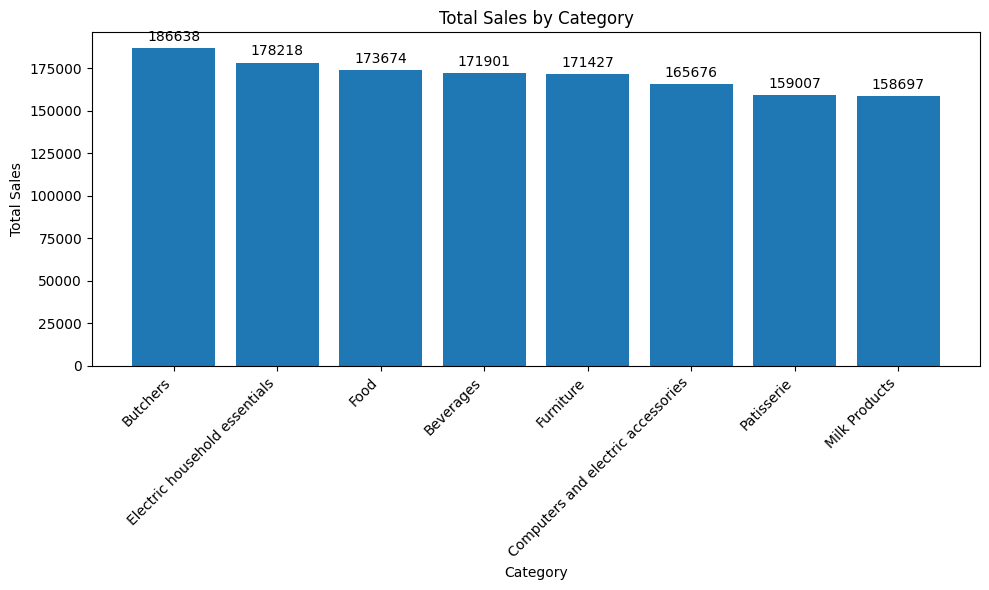

Category
Butchers                              186638.5
Electric household essentials         178218.0
Food                                  173674.5
Beverages                             171901.0
Furniture                             171427.0
Computers and electric accessories    165676.5
Patisserie                            159007.0
Milk Products                         158697.0
Name: Total Spent, dtype: float64


In [11]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("retail_store_sales_cleaned.csv")

category_sales = (
    df.groupby("Category")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
bars = plt.bar(category_sales.index, category_sales.values)

plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(category_sales)

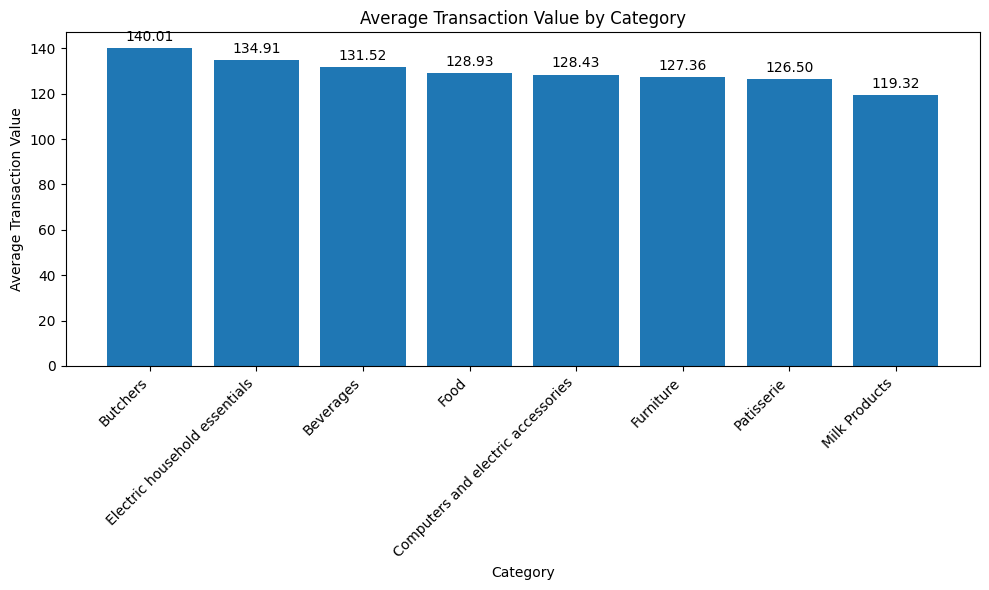

Category
Butchers                              140.013878
Electric household essentials         134.911431
Beverages                             131.523336
Food                                  128.934298
Computers and electric accessories    128.431395
Furniture                             127.360327
Patisserie                            126.497216
Milk Products                         119.321053
Name: Total Spent, dtype: float64


In [12]:

category_avg = (
    df.groupby("Category")["Total Spent"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
bars = plt.bar(category_avg.index, category_avg.values)

plt.bar_label(bars, fmt="%.2f", padding=3)
plt.title("Average Transaction Value by Category")
plt.xlabel("Category")
plt.ylabel("Average Transaction Value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(category_avg)

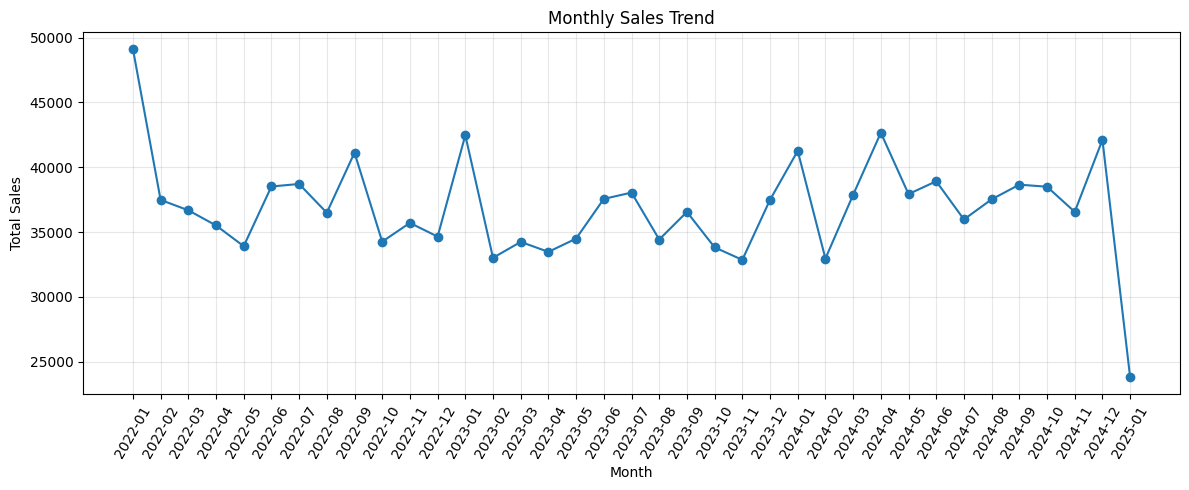

Highest sales month:
2022-01 49141.5

Lowest sales month:
2025-01 23783.0


In [13]:

df["Transaction Date"] = pd.to_datetime(df["Transaction Date"])

monthly_sales = (
    df.groupby(df["Transaction Date"].dt.to_period("M"))["Total Spent"]
    .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Highest sales month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest sales month:")
print(monthly_sales.idxmin(), monthly_sales.min())

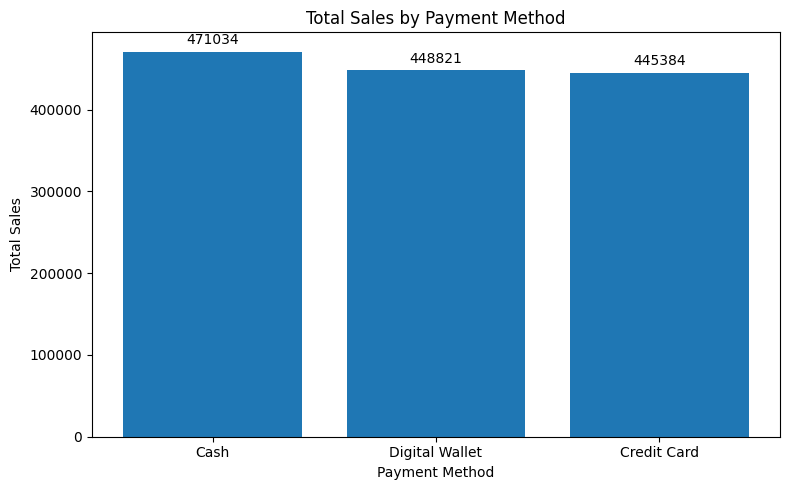

Payment Method
Cash              471034.0
Digital Wallet    448821.0
Credit Card       445384.5
Name: Total Spent, dtype: float64


In [14]:

payment_sales = (
    df.groupby("Payment Method")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
bars = plt.bar(payment_sales.index, payment_sales.values)

plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

print(payment_sales)

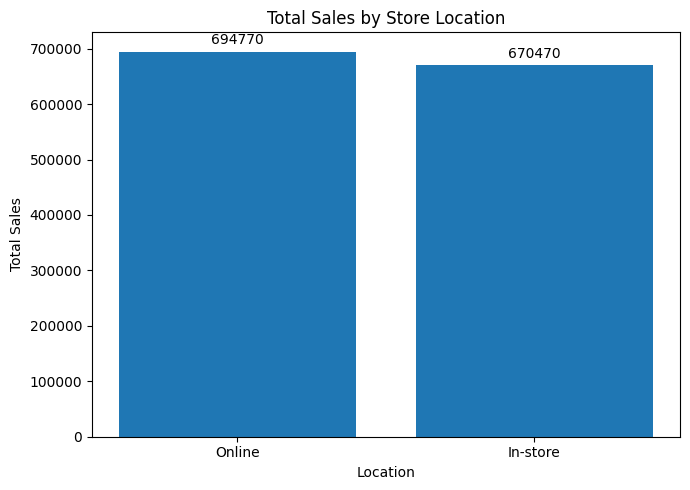

Location
Online      694769.5
In-store    670470.0
Name: Total Spent, dtype: float64


In [15]:

location_sales = (
    df.groupby("Location")["Total Spent"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
bars = plt.bar(location_sales.index, location_sales.values)

plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("Total Sales by Store Location")
plt.xlabel("Location")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

print(location_sales)

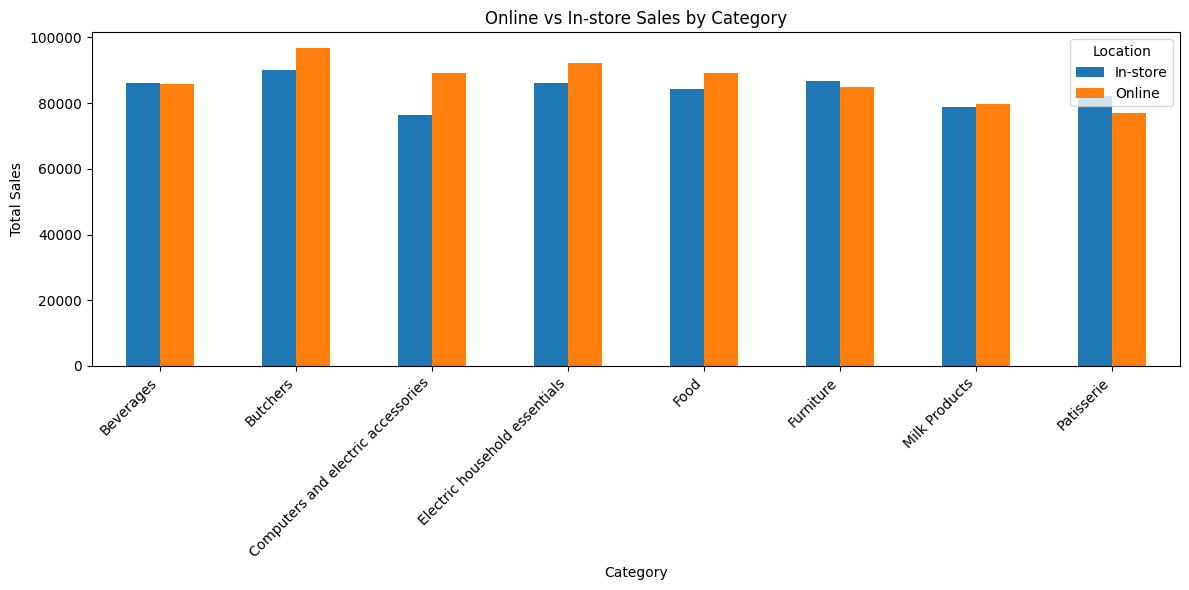

Location                            In-store   Online
Category                                             
Beverages                            85978.5  85922.5
Butchers                             89938.0  96700.5
Computers and electric accessories   76368.0  89308.5
Electric household essentials        86126.0  92092.0
Food                                 84418.0  89256.5
Furniture                            86663.5  84763.5
Milk Products                        78947.5  79749.5
Patisserie                           82030.5  76976.5


In [16]:

location_category_sales = df.pivot_table(
    index="Category",
    columns="Location",
    values="Total Spent",
    aggfunc="sum",
    fill_value=0
)

location_category_sales.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Online vs In-store Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Location")
plt.tight_layout()
plt.show()

print(location_category_sales)

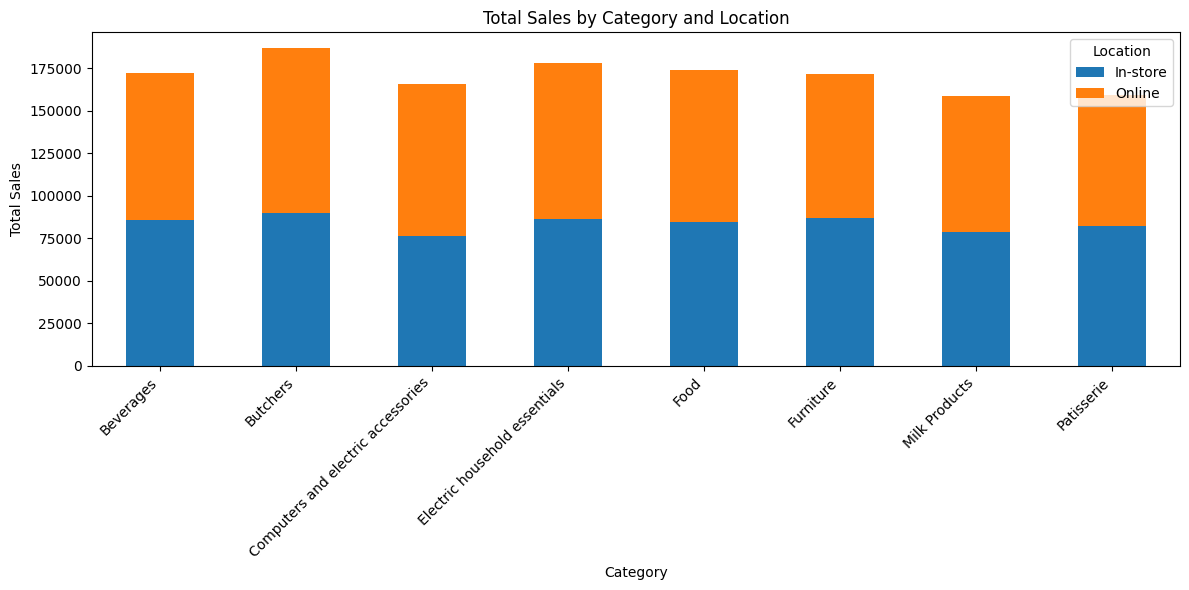

In [17]:

location_category_sales.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Total Sales by Category and Location")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Location")
plt.tight_layout()
plt.show()